In [1]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_ind
from matplotlib.lines import Line2D
from matplotlib.transforms import offset_copy
from matplotlib.ticker import LogLocator, LogFormatterMathtext
import figure_style as fs
from scipy.stats import t as t_dist
from matplotlib.patches import Patch
from matplotlib.ticker import FixedLocator, StrMethodFormatter

In [2]:
# Get the data 
pathB = "../data_files/tumor_volume/GE681B final.xlsx"

# Read the data into pandas
xlsB = pd.ExcelFile(pathB)

In [3]:
# Parse Excel file into one big dataframe with all data

# Parse all sheets in excel file into DataFrames and put them into a list
dfs = []
names = xlsB.sheet_names

# Start with pre-enrollment data
for i in range(0, 7):
    sheet = xlsB.parse(i, skiprows=[0, 1, 2, 3])[['Tumour ID ', 'Date of Birth', 'Cell injection date', 'MCMS \nMouse ID', "Volume (mm3)"]].truncate(after=35)
    sheet["Measurement Date"] = names[i].strip().split(" ")[-1]
    dfs.append(sheet)

# Add post-enrollment data
for i in range(7, len(names)):
    sheet = xlsB.parse(i, skiprows=[0, 1, 2, 3])[["Cohort", 'Tumour ID ', 'Date of Birth', 'Cell injection date', 'MCMS \nMouse ID', "Volume (mm3)"]].truncate(after=35)
    sheet["Measurement Date"] = names[i].strip().split(" ")[-1]
    dfs.append(sheet)

# Join all DataFrames together into one dataset, remove spaces from column names, and remove fully empty rows
temp_data = pd.concat(dfs, join="outer", ignore_index=True)
temp_data = temp_data.rename(columns=lambda x: x.strip())
temp_data.dropna(subset=["Tumour ID"], inplace=True)
temp_data.dropna(subset=["MCMS \nMouse ID"], inplace=True)

# Remove rows from initial measurement period where mice have already been moved to enrollment
temp_data.drop_duplicates(subset=['MCMS \nMouse ID', "Measurement Date"], keep="last", inplace=True)

# Export to a csv so endpoints can be manually added
temp_data.to_csv("../data_files/tumor_volume/tumor_volume_treatment_temp.csv", index=False)

In [4]:
# Import the csv with endpoints added manually from "GE681B final.xlsx"
data = pd.read_csv("../data_files/tumor_volume/tumor_volume_treatment_endpts.csv")

# Convert Measurement date to datetime
data["Measurement Date"] = pd.to_datetime(data["Measurement Date"])

# Add days post-injection column
data["Days Post-Injection"] = (data["Measurement Date"] - pd.to_datetime(data["Cell injection date"])).dt.days

# Add cohort to data pre-enrollment
mice_cohorts = data.drop_duplicates(subset=["MCMS \nMouse ID"], keep="last", ignore_index=True)[["MCMS \nMouse ID", "Cohort"]].dropna()
mice_cohorts["Cohort"] = mice_cohorts["Cohort"].str.split(" ").str[-1].str.split("-").str[-1]
mice_cohorts.set_index("MCMS \nMouse ID", inplace=True)
mouse_cohorts = mice_cohorts.to_dict()

data["Cohort"] = data["MCMS \nMouse ID"].apply(lambda x: mouse_cohorts["Cohort"].get(x))

# Add treatment window to dataframe 
treatment = {"STG139-X5": "14-Apr-22", "STG201-X5": "24-Mar-22", "IC07-X5": "31-Mar-22", "AB040-X5": "31-Mar-22"}

data["Treatment Start"] = pd.to_datetime(data["Tumour ID"].apply(lambda x: treatment.get(x)), format="%d-%b-%y")
data["Treatment End"] = (data["Treatment Start"] + pd.to_timedelta(6, unit="W"))
data["Treatment Start Delta"] = (data["Treatment Start"] - pd.to_datetime(data["Cell injection date"])).dt.days
data["Treatment End Delta"] = (data["Treatment End"] - pd.to_datetime(data["Cell injection date"])).dt.days

# Remove datapoints where the tumor volume is the same between weeks once measurements have
# stopped. A repeated volume followed later by a new volume was measured again, so it is kept 
def internal_repeats(g):
    """Index of one mouse's rows that repeat an earlier volume but are followed by a new one."""
    vols, seen, rows = g["Volume (mm3)"].tolist(), set(), []
    for j, v in enumerate(vols):
        if v in seen and any(w not in seen for w in vols[j + 1:]):
            rows.append(g.index[j])
        seen.add(v)
    return rows


removed = data.drop_duplicates(subset=['MCMS \nMouse ID', "Volume (mm3)"], keep="first", inplace=False)
zeros = data[data["Volume (mm3)"] == 0]
measurable = data[data["Volume (mm3)"] > 0].sort_values("Days Post-Injection")
internal = data.loc[[i for _, g in measurable.groupby('MCMS \nMouse ID') for i in internal_repeats(g)]]
# back into the measurement order, so each mouse's rows run chronologically
filtered = (pd.concat([removed, zeros, internal])
            .drop_duplicates(subset=["MCMS \nMouse ID", "Measurement Date"], keep='first')
            .sort_index().reset_index(drop=True))

# Save final secondary tumor volume dataframe
filtered.to_csv("../data_files/tumor_volume/secondary_cohort_tumor_volume.csv", index=False)

/var/folders/gl/t33602fx3qzf2pkt1spgffn40000gn/T/ipykernel_15626/1325026737.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data["Measurement Date"] = pd.to_datetime(data["Measurement Date"])


saved fig1B_tumor_growth_curves: 3.842 x 4.211 in


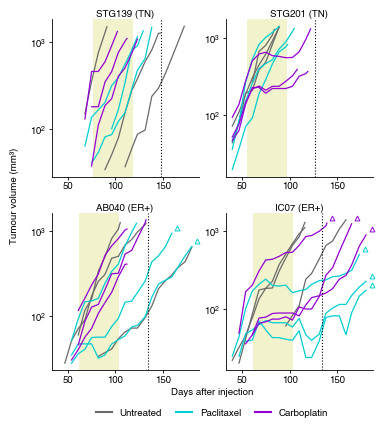

In [5]:
# Graph tumor volume (Figure 1B)
tumor_ids = ['STG139-X5', 'STG201-X5', 'AB040-X5', 'IC07-X5']
cohorts = ["Untreated", "Paclitaxel", "Carboplatin"]
COHORT_COLORS = {"Untreated": "dimgrey", "Paclitaxel": "darkturquoise", "Carboplatin": "darkviolet"}

subtype = {"AB040": "ER+", "IC07": "ER+", "STG139": "TN", "STG201": "TN"}
LATE_GROWTH_DAYS = 30     

# Layout in inches: two rows of two panels, the shared axis titles and the legend outside them
fig = fs.new_panel(3.842, 4.211)
left, right, top, bottom_space = 0.43, 0.2, 0.15, 0.55
wgap, hgap = 0.27, 0.36
panel_w = (3.842 - left - right - wgap) / 2
panel_h = (4.211 - top - bottom_space - hgap) / 2
axes = fs.inch_grid(fig, left, top, 2, 2, panel_w, panel_h, wgap, hgap)
late_growers = []

for item, ax in zip(tumor_ids, axes.ravel()):
    model = item.split("-")[0]
    to_the_right = offset_copy(ax.transData, fig=fig, x=4, y=4, units="points")
    for cohort in cohorts:
        color = COHORT_COLORS[cohort]
        for mouse in filtered.loc[((filtered["Tumour ID"] == item) & (filtered["Cohort"] == cohort))]["MCMS \nMouse ID"].unique():
            dataset = filtered.loc[(filtered["Tumour ID"] == item) & (filtered["MCMS \nMouse ID"] == mouse) & (filtered["Volume (mm3)"] > 0)]
            ax.plot(dataset["Days Post-Injection"], dataset["Volume (mm3)"], color=color, linewidth=0.9)

            last = dataset.sort_values("Days Post-Injection").iloc[-1]
            end = last["Treatment End Delta"]
            if cohort != "Untreated" and last["Days Post-Injection"] > end + LATE_GROWTH_DAYS:
                ax.plot([last["Days Post-Injection"]], [last["Volume (mm3)"]], marker="^",
                        markersize=3.5, markerfacecolor="white", markeredgecolor=color,
                        markeredgewidth=0.7, linestyle="none", transform=to_the_right,
                        clip_on=False, zorder=5)
                late_growers.append({"model": model, "cohort": cohort, "mouse": mouse,
                                     "last_measurement_day": int(last["Days Post-Injection"]),
                                     "days_after_treatment_end": int(last["Days Post-Injection"] - end)})
    ax.axvspan(dataset["Treatment Start Delta"].iloc[0], dataset["Treatment End Delta"].iloc[0], facecolor='y', alpha=0.2, linewidth=0)
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10))
    ax.yaxis.set_major_formatter(LogFormatterMathtext())
    ax.yaxis.minorticks_off()
    ax.set_title(f"{model} ({subtype[model]})")
    ax.spines[['right', 'top']].set_visible(False)
    ax.axvline(x=dataset["Treatment End Delta"].iloc[0]+LATE_GROWTH_DAYS, color='black', linestyle=':', linewidth=0.8)

x_limits = [ax.get_xlim() for ax in axes.ravel()]
for ax in axes.ravel():
    ax.set_xlim(min(lo for lo, _ in x_limits), max(hi for _, hi in x_limits))
    ax.set_xticks([50, 100, 150])

fs.fig_text(fig, left + panel_w + wgap / 2, 4.211 - bottom_space + 0.22, "Days after injection", ha="center", va="center")
fs.fig_text(fig, 0.06, top + panel_h + hgap / 2, "Tumour volume (mm³)", ha="center", va="center", rotation="vertical")
handles = [Line2D([0], [0], color=COHORT_COLORS[c], lw=1.5, label=c) for c in cohorts]
fig.legend(handles=handles, loc="upper center", ncol=3, bbox_to_anchor=((left + panel_w + wgap / 2) / 3.842, 0.05),
           handlelength=1.6, columnspacing=1.5, borderaxespad=0)
fs.save_panel(fig, "fig1B_tumor_growth_curves")
plt.show()

late = pd.DataFrame(late_growers)
late.to_csv("../data_files/tumor_volume/tumor_growth_late_growing_treated.csv", index=False)

In [ ]:
# Parameters and helpers for the Δ-slope analysis 
PHASE_DAYS = 21                   # a phase spans 3 weeks
PHASE_STEP_DAYS = 7               # a window moves a week at a time when it holds too few
MIN_POINTS = 2                    # fewest measurements a slope may be fitted to
TREATED_PHASE_A_CUTOFF_DAYS = 14  # phase (a) stops before the third week of treatment
TREATED_PHASE_A_FALLBACK = True   # a treated mouse with too few measurements before the
                                  # cutoff uses its first MIN_POINTS measurements instead
                                  # of being excluded 
MOUSE_ID = "MCMS \nMouse ID"
ARMS = ["Paclitaxel", "Carboplatin"]

def assign_phases(g, start, end, untreated, untreated_gap_weeks=None):
    # Pick the measurements for phase (a) and phase (b) of one replicate
    g = g.sort_values("Days Post-Injection")
    measurable = g["Volume (mm3)"] > 0        
    days = g.loc[measurable, "Days Post-Injection"].to_numpy(float)
    vol = g.loc[measurable, "Volume (mm3)"].to_numpy(float)
    out = {"a_days": np.array([]), "a_vol": np.array([]), "b_days": np.array([]),
           "b_vol": np.array([]), "n_measurable": len(days), "phase_b_window_days": np.nan,
           "phase_a_fallback": False, "excluded": None}
    if len(days) < 2 * MIN_POINTS:
        out["excluded"] = f"only {len(days)} measurable measurement(s)"
        return out

    if untreated:
        first = days[0]
        a_idx = [i for i, d in enumerate(days) if first <= d < first + PHASE_DAYS]
        if len(a_idx) < MIN_POINTS:
            out["excluded"] = f"untreated; fewer than {MIN_POINTS} measurements in weeks 1-3"
            return out
        b_idx = []
        b_start = first + PHASE_DAYS + untreated_gap_weeks * PHASE_STEP_DAYS
        while b_start >= first + PHASE_DAYS:    # slide earlier, never overlapping phase (a)
            b_idx = [i for i, d in enumerate(days)
                     if b_start <= d < b_start + PHASE_DAYS and i not in a_idx]
            if len(b_idx) >= MIN_POINTS:
                break
            b_start -= PHASE_STEP_DAYS
        if len(b_idx) < MIN_POINTS:
            out["excluded"] = (f"untreated; fewer than {MIN_POINTS} measurements in any 3-week "
                               f"window after weeks 1-3")
            return out
        out["phase_b_window_days"] = PHASE_DAYS
    else:
        cutoff = min(days[0] + PHASE_DAYS, start + TREATED_PHASE_A_CUTOFF_DAYS)
        a_idx = [i for i, d in enumerate(days) if d < cutoff]
        if len(a_idx) < MIN_POINTS:
            if not TREATED_PHASE_A_FALLBACK:
                out["excluded"] = (f"treated; fewer than {MIN_POINTS} measurements before day "
                                   f"{int(cutoff)}")
                return out
            a_idx = list(range(MIN_POINTS))    # first measurements, wherever they fall
            out["phase_a_fallback"] = True
        width = PHASE_DAYS
        while True:                             # widen only as far as treatment start
            b_idx = [i for i, d in enumerate(days)
                     if end - width < d <= end and d >= start and i not in a_idx]
            if len(b_idx) >= MIN_POINTS or end - width <= start:
                break
            width += PHASE_STEP_DAYS
        if len(b_idx) < MIN_POINTS:
            out["excluded"] = (f"treated; fewer than {MIN_POINTS} measurements on treatment "
                               f"after phase (a)")
            return out
        out["phase_b_window_days"] = width

    out.update(a_days=days[a_idx], a_vol=vol[a_idx], b_days=days[b_idx], b_vol=vol[b_idx])
    return out

def slope(days, values):
    return np.polyfit(days, values, 1)[0]

def gap_measurements(g, a_days, b_days):
    # Measurements taken strictly between the last phase (a) and first phase (b) day
    d = g.loc[g["Volume (mm3)"] > 0, "Days Post-Injection"]
    return int(((d > a_days[-1]) & (d < b_days[0])).sum())

def mean_ci(x, conf=0.95):
    # Mean with a two-sided t confidence interval (NaN CI when n < 2)
    x = np.asarray(x, float)
    n = len(x)
    if n < 2:
        return (x.mean() if n else np.nan), np.nan, np.nan
    mean = x.mean()
    sem = x.std(ddof=1) / np.sqrt(n)
    lo, hi = t_dist.interval(conf, n - 1, loc=mean, scale=sem)
    return mean, lo, hi

def diff_ci(x, y, conf=0.95):
    # Mean(x) - mean(y), pooled-variance two-sided CI (matches ttest_ind)
    x, y = np.asarray(x, float), np.asarray(y, float)
    n1, n2 = len(x), len(y)
    df = n1 + n2 - 2
    sp = np.sqrt(((n1 - 1) * x.var(ddof=1) + (n2 - 1) * y.var(ddof=1)) / df)
    se = sp * np.sqrt(1 / n1 + 1 / n2)
    diff = x.mean() - y.mean()
    lo, hi = t_dist.interval(conf, df, loc=diff, scale=se)
    return diff, lo, hi

In [ ]:
# Slopes in each phase and Δ slope for every replicate
def fmt_days(d):
    return ";".join(str(int(x)) for x in d)

def span(d):
    return int(d[-1] - d[0]) if len(d) else 0

def treated_gap_by_model():
    """Measurements each model's treated mice leave between their phases, averaged and
    rounded up. Treated phases do not depend on the untreated gap, so this can be
    measured before the untreated mice are placed. Returns {model: weeks}."""
    gaps = {}
    for item in tumor_ids:
        s = filtered[filtered["Tumour ID"] == item]
        start, end = s["Treatment Start Delta"].iloc[0], s["Treatment End Delta"].iloc[0]
        per_mouse = []
        for arm in ARMS:
            for mouse in sorted(s[s["Cohort"] == arm][MOUSE_ID].unique()):
                g = s[s[MOUSE_ID] == mouse]
                ph = assign_phases(g, start, end, untreated=False)
                if ph["excluded"] is None:
                    per_mouse.append(gap_measurements(g, ph["a_days"], ph["b_days"]))
        if not per_mouse:
            raise ValueError(f"{item}: no included treated mice to set the untreated gap from")
        gaps[item[:-3]] = int(np.ceil(np.mean(per_mouse) - 1e-9))
    return gaps

MATCHED_GAP_WEEKS = treated_gap_by_model()

def build_replicates():
    """Phase assignment, slopes and Δ slope for every replicate, each model's untreated
    mice placed with its matched gap."""
    rows = []
    for item in tumor_ids:
        model = item[:-3]
        s = filtered[filtered["Tumour ID"] == item]
        start, end = s["Treatment Start Delta"].iloc[0], s["Treatment End Delta"].iloc[0]
        for cohort in ["Untreated"] + ARMS:
            for mouse in sorted(s[s["Cohort"] == cohort][MOUSE_ID].unique()):
                ph = assign_phases(s[s[MOUSE_ID] == mouse], start, end,
                                   untreated=(cohort == "Untreated"),
                                   untreated_gap_weeks=MATCHED_GAP_WEEKS[model])
                row = {
                    "model": model, "subtype": subtype[model],
                    "cohort": cohort, "mouse": mouse,
                    "treatment_start_day": int(start), "treatment_end_day": int(end),
                    "included": ph["excluded"] is None,
                    "n_measurable_measurements": ph["n_measurable"],
                    "n_pre": len(ph["a_days"]), "n_post": len(ph["b_days"]),
                    "pre_days": fmt_days(ph["a_days"]), "post_days": fmt_days(ph["b_days"]),
                    "pre_span_days": span(ph["a_days"]), "post_span_days": span(ph["b_days"]),
                    "pre_enters_treatment_window": bool((ph["a_days"] >= start).any()),
                    "phase_b_window_days": ph["phase_b_window_days"],
                    "phase_a_fallback": ph["phase_a_fallback"],
                    "phase_gap_days": (int(ph["b_days"][0] - ph["a_days"][-1])
                                       if len(ph["a_days"]) and len(ph["b_days"]) else np.nan),
                    "phase_b_starts_days_before_end": (int(end - ph["b_days"][0])
                                                       if len(ph["b_days"]) else np.nan),
                    "post_after_treatment_end": bool((ph["b_days"] > end).any()),
                    "exclusion_reason": ph["excluded"] or "",
                }
                if ph["excluded"] is None:
                    row["slope_pre_mm3_per_day"] = slope(ph["a_days"], ph["a_vol"])
                    row["slope_post_mm3_per_day"] = slope(ph["b_days"], ph["b_vol"])
                    row["delta_slope_mm3_per_day"] = (row["slope_post_mm3_per_day"]
                                                      - row["slope_pre_mm3_per_day"])
                rows.append(row)
    return pd.DataFrame(rows)

replicates = build_replicates()
inc = replicates[replicates["included"]]
phase_detail = replicates.set_index("mouse").to_dict("index")   

replicates.to_csv("../data_files/tumor_volume/tumor_growth_delta_slope_per_replicate.csv", index=False)


In [ ]:
# Supplementary tables: one row per mouse, one row per model/cohort
# cohort_stats is the only place the treated-vs-untreated comparison is computed
def cohort_stats(reps):
    """Per model and cohort: mean slopes, mean Δ with 95% CI, and for the treated
    cohorts the difference from untreated with its CI and a two-tailed t"""
    ok = reps[reps["included"]]
    rows = []
    for item in tumor_ids:
        model = item[:-3]
        untreated = ok[(ok["model"] == model) &
                       (ok["cohort"] == "Untreated")]["delta_slope_mm3_per_day"].values
        for cohort in ["Untreated"] + ARMS:
            sub = ok[(ok["model"] == model) & (ok["cohort"] == cohort)].sort_values("mouse")
            delta = sub["delta_slope_mm3_per_day"].values
            mean_delta, lo, hi = mean_ci(delta)
            row = {"model": model, "subtype": subtype[model], "cohort": cohort,
                   "comparison": "reference" if cohort == "Untreated" else f"{cohort} vs Untreated",
                   "n": len(sub),
                   "mean_slope_phase_a_mm3_per_day": sub["slope_pre_mm3_per_day"].mean(),
                   "mean_slope_phase_b_mm3_per_day": sub["slope_post_mm3_per_day"].mean(),
                   "mean_delta_slope_mm3_per_day": mean_delta,
                   "delta_CI95_low": lo, "delta_CI95_high": hi}
            if cohort == "Untreated":
                row["test"] = "reference cohort"
            elif len(delta) >= 2 and len(untreated) >= 2:
                diff, d_lo, d_hi = diff_ci(delta, untreated)
                t_stat, pval = ttest_ind(delta, untreated)
                row.update(test="Δ vs untreated, two-tailed t", n_untreated=len(untreated),
                           difference_in_mean_delta=diff, difference_CI95_low=d_lo,
                           difference_CI95_high=d_hi, t_statistic=t_stat,
                           df=len(delta) + len(untreated) - 2, p_two_tailed=pval)
            rows.append(row)
    return pd.DataFrame(rows)

per_mouse = inc.sort_values(["model", "cohort", "mouse"])[
    ["model", "subtype", "cohort", "mouse", "n_pre", "n_post", "pre_days", "post_days",
     "pre_span_days", "post_span_days", "phase_a_fallback",
     "slope_pre_mm3_per_day", "slope_post_mm3_per_day", "delta_slope_mm3_per_day"]
].rename(columns={"n_pre": "n_measurements_phase_a", "n_post": "n_measurements_phase_b",
                  "pre_days": "phase_a_days", "post_days": "phase_b_days",
                  "pre_span_days": "phase_a_span_days", "post_span_days": "phase_b_span_days",
                  "slope_pre_mm3_per_day": "slope_phase_a_mm3_per_day",
                  "slope_post_mm3_per_day": "slope_phase_b_mm3_per_day"})

per_cohort = cohort_stats(replicates)

per_mouse.to_csv("../data_files/tumor_volume/tumor_growth_delta_slope_per_mouse.csv", index=False)
per_cohort.to_csv("../data_files/tumor_volume/tumor_growth_delta_slope_per_cohort.csv", index=False)


saved figS1A_tumor_growth_curves_phases_per_mouse: 6.274 x 6.288 in


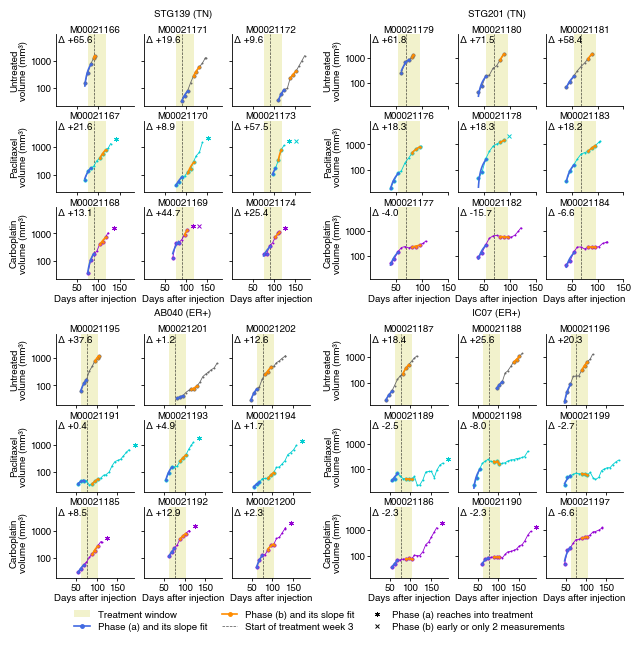

In [ ]:
PRE_COLOR, POST_COLOR = "royalblue", "darkorange"
COHORTS = ["Untreated"] + ARMS

def phase_points(g, days_str):
    # Rows of g whose measurement day is listed in a phase's day string
    days = [int(d) for d in days_str.split(";")] if days_str else []
    return g[g["Days Post-Injection"].isin(days)]

def phase_b_short_or_early(info):
    """A treated mouse's phase (b) holds only 2 measurements (a full phase holds 3 weekly
    measurements), or its window had to widen back past the last 3 treatment weeks."""
    return info["n_post"] < 3 or info["phase_b_window_days"] > PHASE_DAYS

ASTERISK = (6, 2, 0)                       

FIG_W, FIG_H = 6.274, 6.288
LEGEND_H = 0.3
NCOLS = filtered.groupby(["Tumour ID", "Cohort"])[MOUSE_ID].nunique().max()
BLOCK_W, BLOCK_H = FIG_W / 2, (FIG_H - LEGEND_H) / 2
MARGIN_L, MARGIN_R, MARGIN_T, MARGIN_B = 0.5, 0.1, 0.27, 0.28   
GAP_W, GAP_H = 0.1, 0.15
PANEL_W = (BLOCK_W - MARGIN_L - MARGIN_R - (NCOLS - 1) * GAP_W) / NCOLS
PANEL_H = (BLOCK_H - MARGIN_T - MARGIN_B - (len(COHORTS) - 1) * GAP_H) / len(COHORTS)
fig = fs.new_panel(FIG_W, FIG_H)

for b, item in enumerate(tumor_ids):
    model = item[:-3]
    block_left, block_top = (b % 2) * BLOCK_W, (b // 2) * BLOCK_H
    s = filtered[filtered["Tumour ID"] == item]
    measured = s[s["Volume (mm3)"] > 0]
    start, end = s["Treatment Start Delta"].iloc[0], s["Treatment End Delta"].iloc[0]
    axes = fs.inch_grid(fig, block_left + MARGIN_L, block_top + MARGIN_T, len(COHORTS), NCOLS, PANEL_W, PANEL_H,
                        GAP_W, GAP_H)
    fs.fig_text(fig, block_left + MARGIN_L + (NCOLS * PANEL_W + (NCOLS - 1) * GAP_W) / 2, block_top + 0.02,
                f"{model} ({subtype[model]})", ha="center", va="top")

    for r, cohort in enumerate(COHORTS):
        colour = COHORT_COLORS[cohort]
        mice = sorted(s[s["Cohort"] == cohort][MOUSE_ID].unique())
        for c, ax in enumerate(axes[r]):
            if c >= len(mice):
                ax.set_visible(False)
                continue
            mouse = mice[c]
            g = measured[measured[MOUSE_ID] == mouse].sort_values("Days Post-Injection")
            info = phase_detail[mouse]

            ax.axvspan(start, end, facecolor="y", alpha=0.2, linewidth=0, zorder=0)
            ax.axvline(start + TREATED_PHASE_A_CUTOFF_DAYS, color="black", linestyle="--",
                       linewidth=0.5, alpha=0.7, zorder=0.5)   # start of treatment week 3
            ax.plot(g["Days Post-Injection"], g["Volume (mm3)"], color=colour, linewidth=0.6, zorder=1)
            ax.scatter(g["Days Post-Injection"], g["Volume (mm3)"], s=2, color=colour, linewidths=0, zorder=2)

            if info["included"]:
                for days_str, phase_colour in [(info["pre_days"], PRE_COLOR),
                                               (info["post_days"], POST_COLOR)]:
                    pts = phase_points(g, days_str)
                    ax.scatter(pts["Days Post-Injection"], pts["Volume (mm3)"], s=6,
                               c=phase_colour, edgecolors=colour, linewidths=0.4, zorder=3)
                    k, b0 = np.polyfit(pts["Days Post-Injection"], pts["Volume (mm3)"], 1)
                    xs = np.linspace(pts["Days Post-Injection"].min(),
                                     pts["Days Post-Injection"].max(), 50)
                    ys = k * xs + b0
                    ax.plot(xs[ys > 0], ys[ys > 0], color=phase_colour, linewidth=1.2, zorder=4)
                label = f"Δ {info['delta_slope_mm3_per_day']:+.1f}"

                marks = [] if cohort == "Untreated" else [
                    (marker, size) for marker, size, on in [
                        (ASTERISK, 3.5, info["pre_enters_treatment_window"]),
                        ("x", 2.5, phase_b_short_or_early(info))] if on]
                for k, (marker, size) in enumerate(marks):
                    at = offset_copy(ax.transData, fig=fig, x=4 + 4.5 * k, y=3, units="points")
                    ax.plot(g["Days Post-Injection"].iloc[-1:], g["Volume (mm3)"].iloc[-1:],
                            marker=marker, markersize=size, markeredgewidth=0.7, color=colour,
                            linestyle="none", transform=at, clip_on=False, zorder=5)
            else:
                label = f"excluded:\n{info['exclusion_reason']}"
            ax.text(0.03, 0.98, label, transform=ax.transAxes, va="top", ha="left",
                    linespacing=1.1, zorder=6)

            ax.set_title(mouse, pad=1.5)
            ax.set_xlim(0, measured["Days Post-Injection"].max() + 12)
            ax.set_yscale("log")
            ax.set_ylim(measured["Volume (mm3)"].min() / 1.5, measured["Volume (mm3)"].max() * 6)
            ax.yaxis.minorticks_off()
            ax.yaxis.set_major_locator(FixedLocator([10, 100, 1000]))
            ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}"))
            ax.set_xticks([50, 100, 150])
            ax.spines[["right", "top"]].set_visible(False)
            ax.tick_params(labelbottom=False, labelleft=(c == 0))
        axes[r, 0].set_ylabel(f"{cohort}\nvolume (mm³)", linespacing=1.0,
                              labelpad=1.5)

    for column in axes.T:                  # x axis on the lowest panel shown in each column
        lowest = [ax for ax in column if ax.get_visible()][-1]
        lowest.set_xlabel("Days after injection", labelpad=1)
        lowest.tick_params(labelbottom=True)

handles = [Patch(facecolor="y", alpha=0.2, label="Treatment window"),
           Line2D([0], [0], color=PRE_COLOR, lw=1.2, marker="o", markersize=2.5,
                  label="Phase (a) and its slope fit"),
           Line2D([0], [0], color=POST_COLOR, lw=1.2, marker="o", markersize=2.5,
                  label="Phase (b) and its slope fit"),
           Line2D([0], [0], color="black", linestyle="--", lw=0.5, alpha=0.7,
                  label="Start of treatment week 3"),
           Line2D([0], [0], color="black", marker=ASTERISK, markersize=3.5, markeredgewidth=0.7,
                  linestyle="none", label="Phase (a) reaches into treatment"),
           Line2D([0], [0], color="black", marker="x", markersize=2.5, markeredgewidth=0.7,
                  linestyle="none", label="Phase (b) early or only 2 measurements")]
fig.legend(handles=handles, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.0), borderaxespad=0.1,
           handlelength=1.6, columnspacing=1.5, labelspacing=0.3)
fs.save_panel(fig, "figS1A_tumor_growth_curves_phases_per_mouse")
plt.show()

figS1B_tumor_growth_phase_slopes_by_cohort: overlapping text: [('Untreated', 'Paclitaxel'), ('Paclitaxel', 'Carboplatin'), ('Untreated', 'Paclitaxel'), ('Paclitaxel', 'Carboplatin')]
saved figS1B_tumor_growth_phase_slopes_by_cohort: 2.815 x 3.061 in


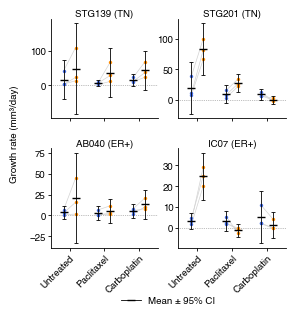

In [10]:
FIG_W, FIG_H = 2.815, 3.061
fig = fs.new_panel(FIG_W, FIG_H)
left, right, top, wgap, hgap = 0.42, 0.04, 0.15, 0.2, 0.3
panel_w = (FIG_W - left - right - wgap) / 2
panel_h = (FIG_H - top - hgap - 0.62) / 2
axes = fs.inch_grid(fig, left, top, 2, 2, panel_w, panel_h, wgap, hgap)
OFFSET = 0.17

for item, ax in zip(tumor_ids, axes.ravel()):
    model = item[:-3]
    d = inc[inc["model"] == model]
    for i, cohort in enumerate(COHORTS):
        sub = d[d["cohort"] == cohort]
        xa, xb = i - OFFSET, i + OFFSET
        for _, r in sub.iterrows():                      
            ax.plot([xa, xb], [r["slope_pre_mm3_per_day"], r["slope_post_mm3_per_day"]],
                    color="lightgrey", linewidth=0.5, zorder=1)
        ax.scatter([xa] * len(sub), sub["slope_pre_mm3_per_day"], s=6, color=PRE_COLOR, linewidths=0, zorder=3)
        ax.scatter([xb] * len(sub), sub["slope_post_mm3_per_day"], s=6, color=POST_COLOR, linewidths=0, zorder=3)
        for x, vals in [(xa, sub["slope_pre_mm3_per_day"].values),
                        (xb, sub["slope_post_mm3_per_day"].values)]:
            m, lo, hi = mean_ci(vals)
            ax.errorbar(x, m, yerr=[[m - lo], [hi - m]], fmt="_", color="black",
                        markersize=6, elinewidth=0.6, capsize=1.5, capthick=0.6, zorder=4)

    ax.axhline(0, color="grey", linewidth=0.5, linestyle=":")
    ax.set_xticks(range(len(COHORTS)))
    ax.set_xticklabels(COHORTS if ax in axes[-1] else [], rotation=45, ha="right", rotation_mode="anchor")
    ax.set_xlim(-0.55, len(COHORTS) - 0.45)
    ax.set_title(f"{model} ({subtype[model]})")
    ax.spines[["right", "top"]].set_visible(False)

fs.fig_text(fig, 0.06, top + panel_h + hgap / 2, "Growth rate (mm³/day)", ha="center", va="center",
            rotation="vertical")   

handles = [Line2D([0], [0], color="black", lw=0.6, marker="_", markersize=6, label="Mean ± 95% CI")]
fig.legend(handles=handles, loc="lower center", ncol=1, bbox_to_anchor=((left + panel_w + wgap / 2) / FIG_W, 0.0),
           borderaxespad=0.1)
fs.save_panel(fig, "figS1B_tumor_growth_phase_slopes_by_cohort")
plt.show()

saved fig1C_tumor_growth_delta_slope_by_cohort: 3.621 x 3.774 in


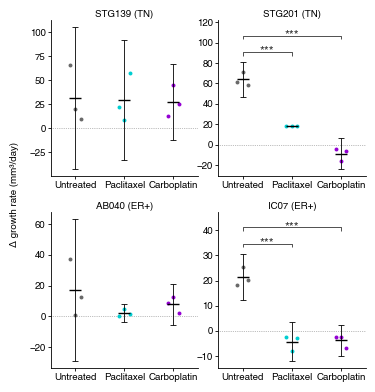

In [11]:
SIG_ALPHA = fs.SIG_ALPHA

FIG_W, FIG_H = 3.621, 3.774
fig = fs.new_panel(FIG_W, FIG_H)
left, right, top, bottom, wgap, hgap = 0.42, 0.05, 0.15, 0.14, 0.2, 0.36
panel_w = (FIG_W - left - right - wgap) / 2
panel_h = (FIG_H - top - bottom - hgap) / 2
axes = fs.inch_grid(fig, left, top, 2, 2, panel_w, panel_h, wgap, hgap)

for i, item in enumerate(tumor_ids):
    model = item[:-3]
    ax = axes[i // 2, i % 2]
    d = inc[inc["model"] == model]
    top_value = -np.inf
    for j, cohort in enumerate(COHORTS):
        vals = d[d["cohort"] == cohort]["delta_slope_mm3_per_day"].values
        jitter = np.linspace(-0.11, 0.11, len(vals)) if len(vals) > 1 else np.zeros(len(vals))
        ax.scatter(j + jitter, vals, s=8, color=COHORT_COLORS[cohort], linewidths=0, zorder=3)
        m, lo, hi = mean_ci(vals)
        ax.errorbar(j, m, yerr=[[m - lo], [hi - m]], fmt="_", color="black",
                    markersize=8, elinewidth=0.6, capsize=2, capthick=0.6, zorder=4)
        top_value = max(top_value, vals.max() if len(vals) else -np.inf, hi if np.isfinite(hi) else -np.inf)

    sig = [(COHORTS.index(r["cohort"]), r["p_two_tailed"])
           for _, r in per_cohort[per_cohort["model"] == model].iterrows()
           if pd.notna(r["p_two_tailed"]) and r["p_two_tailed"] < SIG_ALPHA]
    rng = top_value - min(d["delta_slope_mm3_per_day"].min(), 0) or 1
    if sig:
        for k, (j, pval) in enumerate(sorted(sig)):
            y = top_value + rng * (0.10 + 0.17 * k)
            fs.significance_bracket(ax, 0, j, y, pval, tick=rng * 0.035)
        ax.set_ylim(top=y + rng * 0.16)

    ax.axhline(0, color="grey", linewidth=0.5, linestyle=":")
    ax.set_xticks(range(len(COHORTS)))
    ax.set_xticklabels(COHORTS)
    ax.set_xlim(-0.5, len(COHORTS) - 0.5)
    ax.set_title(f"{model} ({subtype[model]})")
    ax.spines[["right", "top"]].set_visible(False)

fs.fig_text(fig, 0.06, top + panel_h + hgap / 2, "Δ growth rate (mm³/day)", ha="center", va="center",
            rotation="vertical")  
fs.save_panel(fig, "fig1C_tumor_growth_delta_slope_by_cohort")
plt.show()

saved figS1C_tumor_growth_delta_slope_difference: 4.710 x 1.856 in


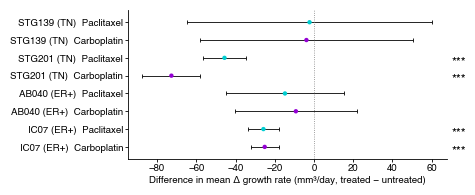

In [ ]:
def forest(ax, frame, est, lo, hi, xlabel, labels=None, colours=None, marker_size=30, star_size=11):
    ypos = np.arange(len(frame))[::-1]
    ax.errorbar(frame[est], ypos, xerr=[frame[est] - frame[lo], frame[hi] - frame[est]],
                fmt="none", ecolor="black", elinewidth=0.6, capsize=1.5, capthick=0.6, zorder=1)
    ax.scatter(frame[est], ypos, s=marker_size, c=colours, linewidths=0, zorder=2)
    ax.axvline(0, color="grey", linestyle=":", linewidth=0.6)
    ax.set_yticks(ypos)
    ax.set_ylim(-0.7, len(frame) - 0.3)
    if labels is not None:
        ax.set_yticklabels(labels)
    ax.set_xlabel(xlabel)
    ax.spines[["right", "top"]].set_visible(False)
    xmax = ax.get_xlim()[1]
    for y, pval in zip(ypos, frame["p_two_tailed"]):
        label = fs.stars(pval)
        if label:
            ax.annotate(label, xy=(xmax, y), xytext=(3, -0.3 * star_size), textcoords="offset points",
                        va="center", ha="left", fontsize=max(star_size, fs.FONT), annotation_clip=False)

eff = per_cohort[per_cohort["p_two_tailed"].notna()].reset_index(drop=True)
EFF_LABELS = [f"{r.model} ({r.subtype})  {r.cohort}" for r in eff.itertuples()]
EFF_COLOURS = [COHORT_COLORS[c] for c in eff["cohort"]]

FIG_W, FIG_H = 4.710, 1.856
fig = fs.new_panel(FIG_W, FIG_H)
ax = fs.inch_axes(fig, 1.22, 0.06, FIG_W - 1.22 - 0.3, FIG_H - 0.06 - 0.3)
forest(ax, eff, "difference_in_mean_delta", "difference_CI95_low", "difference_CI95_high",
       "Difference in mean Δ growth rate (mm³/day, treated − untreated)",
       labels=EFF_LABELS, colours=EFF_COLOURS, marker_size=10, star_size=fs.STAR_FONT)
fs.save_panel(fig, "figS1C_tumor_growth_delta_slope_difference")
plt.show()